# ERM vs Group DRO Results Analysis

Compare the final ERM and Group DRO models on the CivilComments-WILDS test set, including overall performance, worst-group accuracy, identity-label group performance, and the average-versus-worst-group trade-off.

In [ ]:
#from google.colab import drive
#drive.mount("/content/drive")

from pathlib import Path
import os

#PROJECT_ROOT = Path("/content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments")
#if not PROJECT_ROOT.exists():
#    raise FileNotFoundError(PROJECT_ROOT)

#os.chdir(PROJECT_ROOT)
#print("Project root:", Path.cwd())


Mounted at /content/drive
Project root: /content/drive/MyDrive/ele680/ele680-civilComments-20261029T191748Z-1-001/ele680-civilComments


In [2]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
print("Imports successful")


Imports successful


In [3]:
# Notebook expected in notebooks/. If run from project root, remove ../
ERM_DIR = Path("results/erm")
DRO_DIR = Path("results/group_dro")
COMPARISON_DIR = Path("results/comparison")
FIGURE_DIR = Path("figures/results")
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required = [
    ERM_DIR / "test_metrics.json",
    ERM_DIR / "test_group_metrics.csv",
    DRO_DIR / "test_metrics.json",
    DRO_DIR / "test_group_metrics.csv",
]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Missing files:" + ", ".join(missing))
print("All required result files found.")


All required result files found.


## Load Overall Test Metrics


In [4]:
with open(ERM_DIR / "test_metrics.json", encoding="utf-8") as f:
    erm_metrics = json.load(f)
with open(DRO_DIR / "test_metrics.json", encoding="utf-8") as f:
    dro_metrics = json.load(f)
print("ERM:", json.dumps(erm_metrics, indent=2))
print("Group DRO:", json.dumps(dro_metrics, indent=2))


ERM: {
  "accuracy": 0.9227378889474874,
  "precision": 0.6817362571342745,
  "recall": 0.6013911891354753,
  "f1": 0.6390482559571997,
  "worst_group_accuracy": 0.4840510366826156
}
Group DRO: {
  "loss": 0.4468239391128713,
  "accuracy": 0.8440367663678143,
  "precision": 0.4069080039853869,
  "recall": 0.811659489897317,
  "f1": 0.5420639309810862,
  "worst_group_accuracy": 0.651492312330419
}


## Overall Comparison


In [5]:
needed = ["accuracy", "precision", "recall", "f1", "worst_group_accuracy"]
for metric in needed:
    if metric not in erm_metrics or metric not in dro_metrics:
        raise KeyError(f"Missing metric: {metric}")

comparison_df = pd.DataFrame([
    {"Method":"ERM", "Accuracy":erm_metrics["accuracy"], "Precision":erm_metrics["precision"], "Recall":erm_metrics["recall"], "F1":erm_metrics["f1"], "Worst-group Accuracy":erm_metrics["worst_group_accuracy"]},
    {"Method":"Group DRO", "Accuracy":dro_metrics["accuracy"], "Precision":dro_metrics["precision"], "Recall":dro_metrics["recall"], "F1":dro_metrics["f1"], "Worst-group Accuracy":dro_metrics["worst_group_accuracy"]},
])
comparison_df.round(4)


,Method,Accuracy,Precision,Recall,F1,Worst-group Accuracy
0,ERM,0.9227,0.6817,0.6014,0.6390,0.4841
1,Group DRO,0.8440,0.4069,0.8117,0.5421,0.6515


## Metric Changes


In [6]:
erm_row = comparison_df.query("Method == 'ERM'").iloc[0]
dro_row = comparison_df.query("Method == 'Group DRO'").iloc[0]
metrics = ["Accuracy", "Precision", "Recall", "F1", "Worst-group Accuracy"]
changes = {m: float(dro_row[m] - erm_row[m]) for m in metrics}
changes_df = pd.DataFrame({"Metric":changes.keys(), "Change (Group DRO - ERM)":changes.values()})
display(changes_df.round(4))
for m, v in changes.items(): print(f"{m}: {v:+.4f}")


,Metric,Change (Group DRO - ERM)
0,Accuracy,-0.0787
1,Precision,-0.2748
2,Recall,0.2103
3,F1,-0.0970
4,Worst-group Accuracy,0.1674


Accuracy: -0.0787
Precision: -0.2748
Recall: +0.2103
F1: -0.0970
Worst-group Accuracy: +0.1674


## Main Figure: Average vs Worst-Group Accuracy


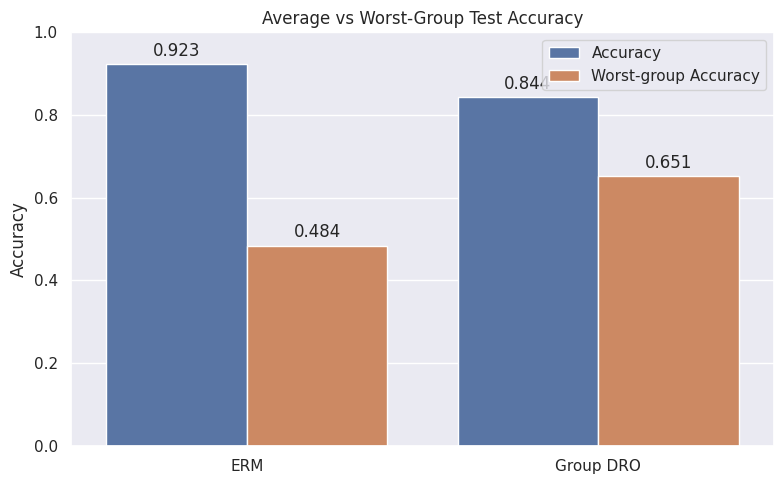

In [7]:
plot_df = comparison_df[["Method","Accuracy","Worst-group Accuracy"]].melt(id_vars="Method", var_name="Metric", value_name="Score")
plt.figure(figsize=(8,5))
ax=sns.barplot(data=plot_df,x="Method",y="Score",hue="Metric")
for container in ax.containers: ax.bar_label(container,fmt="%.3f",padding=3)
plt.ylim(0,1); plt.xlabel(""); plt.ylabel("Accuracy"); plt.title("Average vs Worst-Group Test Accuracy"); plt.legend(title="")
plt.tight_layout(); plt.savefig(FIGURE_DIR/"average_vs_worst_group_accuracy.png",dpi=300,bbox_inches="tight"); plt.show()


## Load and Verify Group-Level Metrics


In [8]:
erm_groups=pd.read_csv(ERM_DIR/"test_group_metrics.csv")
dro_groups=pd.read_csv(DRO_DIR/"test_group_metrics.csv")
expected={"identity","label","label_name","n","accuracy"}
for name,df in [("ERM",erm_groups),("Group DRO",dro_groups)]:
    miss=expected-set(df.columns)
    if miss: raise ValueError(f"{name} missing columns: {sorted(miss)}")
assert set(zip(erm_groups.identity,erm_groups.label))==set(zip(dro_groups.identity,dro_groups.label))
size_check=erm_groups[["identity","label","n"]].merge(dro_groups[["identity","label","n"]],on=["identity","label"],suffixes=("_erm","_dro"),validate="one_to_one")
assert (size_check.n_erm==size_check.n_dro).all()
print("Evaluation groups and group sizes match.")


Evaluation groups and group sizes match.


## Group-Level Comparison


In [9]:
group_comparison=erm_groups[["identity","label","label_name","n","accuracy"]].rename(columns={"accuracy":"ERM_accuracy"}).merge(
    dro_groups[["identity","label","accuracy"]].rename(columns={"accuracy":"GroupDRO_accuracy"}),
    on=["identity","label"],validate="one_to_one")
group_comparison["difference"]=group_comparison.GroupDRO_accuracy-group_comparison.ERM_accuracy
group_comparison["group_name"]=group_comparison.identity+" | "+group_comparison.label_name
erm_worst=group_comparison.sort_values("ERM_accuracy").iloc[0]
dro_worst=group_comparison.sort_values("GroupDRO_accuracy").iloc[0]
display(group_comparison.sort_values("ERM_accuracy").round(4))
print("ERM worst group:",erm_worst[["identity","label_name","n","ERM_accuracy"]])
print("Group DRO worst group:",dro_worst[["identity","label_name","n","GroupDRO_accuracy"]])


,identity,label,label_name,n,ERM_accuracy,GroupDRO_accuracy,difference,group_name
7,christian,1,toxic,1254,0.4841,0.6938,0.2097,christian | toxic
11,other_religions,1,toxic,517,0.5010,0.7408,0.2398,other_religions | toxic
9,muslim,1,toxic,1616,0.5334,0.7277,0.1943,muslim | toxic
5,LGBTQ,1,toxic,1205,0.5494,0.7734,0.2241,LGBTQ | toxic
3,female,1,toxic,2252,0.5662,0.7469,0.1807,female | toxic
1,male,1,toxic,2187,0.5697,0.7398,0.1701,male | toxic
15,white,1,toxic,2208,0.5928,0.7794,0.1866,white | toxic
13,black,1,toxic,1517,0.6084,0.8082,0.1997,black | toxic
12,black,0,non-toxic,3317,0.8701,0.6515,-0.2186,black | non-toxic
14,white,0,non-toxic,5644,0.8762,0.6951,-0.1811,white | non-toxic


ERM worst group: identity        christian
label_name          toxic
n                    1254
ERM_accuracy     0.484051
Name: 7, dtype: object
Group DRO worst group: identity                 black
label_name           non-toxic
n                         3317
GroupDRO_accuracy     0.651492
Name: 12, dtype: object


In [10]:
print("Largest improvements")
display(group_comparison.nlargest(5,"difference")[["group_name","n","ERM_accuracy","GroupDRO_accuracy","difference"]].round(4))
print("Largest decreases")
display(group_comparison.nsmallest(5,"difference")[["group_name","n","ERM_accuracy","GroupDRO_accuracy","difference"]].round(4))


Largest improvements


,group_name,n,ERM_accuracy,GroupDRO_accuracy,difference
11,other_religions | toxic,517,0.5010,0.7408,0.2398
5,LGBTQ | toxic,1205,0.5494,0.7734,0.2241
7,christian | toxic,1254,0.4841,0.6938,0.2097
13,black | toxic,1517,0.6084,0.8082,0.1997
9,muslim | toxic,1616,0.5334,0.7277,0.1943


Largest decreases


,group_name,n,ERM_accuracy,GroupDRO_accuracy,difference
12,black | non-toxic,3317,0.8701,0.6515,-0.2186
4,LGBTQ | non-toxic,3193,0.8954,0.7028,-0.1926
14,white | non-toxic,5644,0.8762,0.6951,-0.1811
8,muslim | non-toxic,5283,0.9137,0.7672,-0.1465
10,other_religions | non-toxic,2947,0.9522,0.8480,-0.1042


## Figure: Accuracy Across Groups


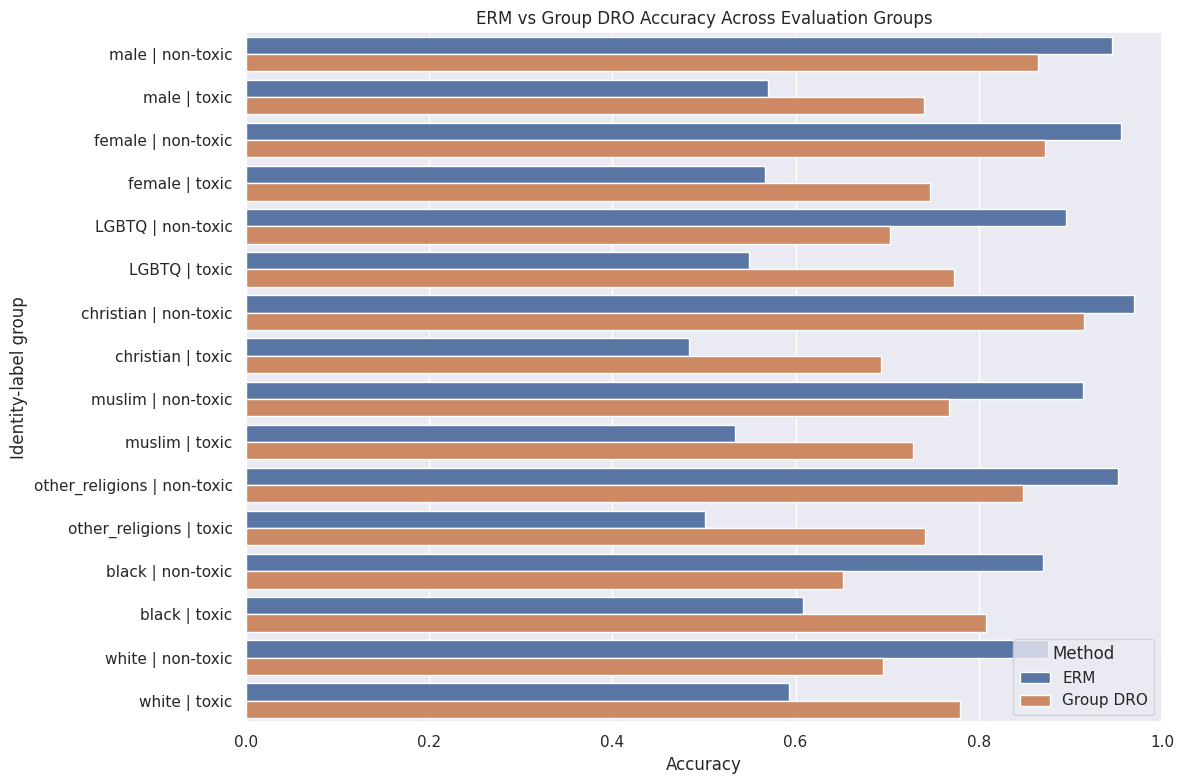

In [11]:
group_plot=group_comparison[["group_name","ERM_accuracy","GroupDRO_accuracy"]].melt(id_vars="group_name",var_name="Method",value_name="Accuracy")
group_plot.Method=group_plot.Method.replace({"ERM_accuracy":"ERM","GroupDRO_accuracy":"Group DRO"})
plt.figure(figsize=(12,8)); sns.barplot(data=group_plot,y="group_name",x="Accuracy",hue="Method")
plt.xlim(0,1); plt.xlabel("Accuracy"); plt.ylabel("Identity-label group"); plt.title("ERM vs Group DRO Accuracy Across Evaluation Groups")
plt.tight_layout(); plt.savefig(FIGURE_DIR/"group_accuracy_comparison.png",dpi=300,bbox_inches="tight"); plt.show()


## Accuracy Change by Group


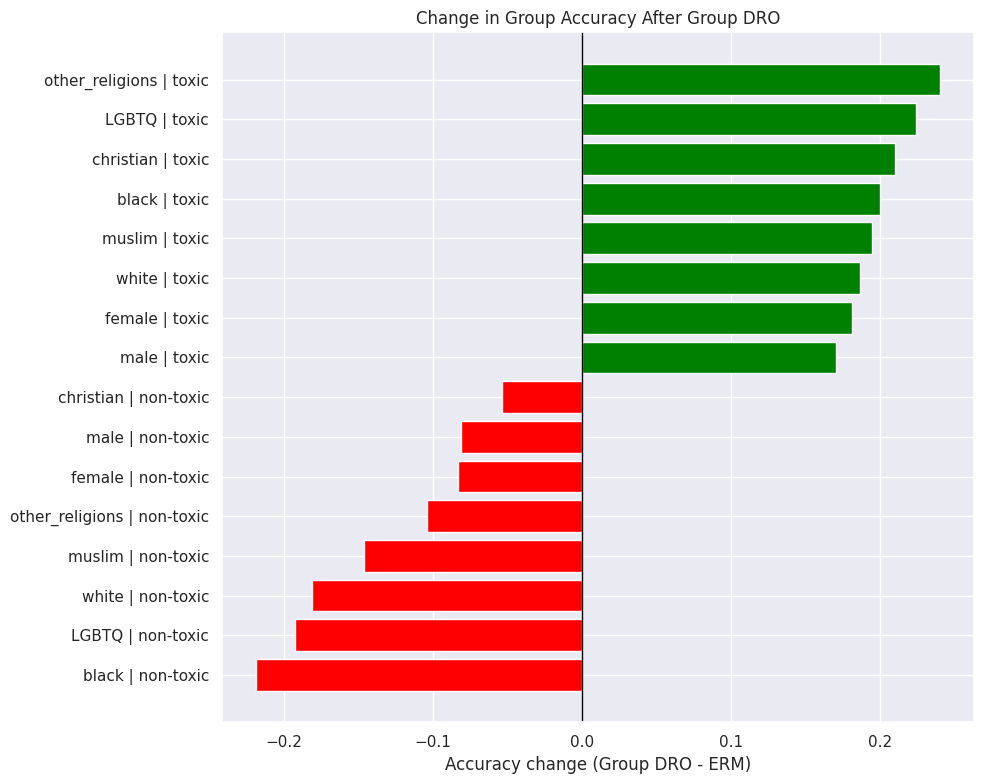

In [12]:
imp=group_comparison.sort_values("difference")
colors=["green" if x>0 else "red" for x in imp.difference]
plt.figure(figsize=(10,8)); plt.barh(imp.group_name,imp.difference,color=colors); plt.axvline(0,color="black",linewidth=1)
plt.xlabel("Accuracy change (Group DRO - ERM)"); plt.title("Change in Group Accuracy After Group DRO")
plt.tight_layout(); plt.savefig(FIGURE_DIR/"group_accuracy_change.png",dpi=300,bbox_inches="tight"); plt.show()


## Group DRO Validation History


,epoch,train_robust_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_worst_group_accuracy,group_0_loss,group_0_weight,group_1_loss,group_1_weight,group_2_loss,group_2_weight,group_3_loss,group_3_weight
0,1,0.401490,0.436453,0.847581,0.408198,0.809098,0.542633,0.632812,0.306388,3.904423e-08,0.405531,0.615679,0.390362,0.033395,0.400940,0.350926
1,2,0.253157,0.366358,0.891402,0.509961,0.722090,0.597764,0.533854,0.347109,2.846253e-01,0.249538,0.347753,0.267285,0.236476,0.245969,0.131145
2,3,0.162021,0.382315,0.901636,0.546392,0.705403,0.615798,0.533854,0.171674,8.719214e-01,0.144907,0.023150,0.153260,0.084679,0.152355,0.020249


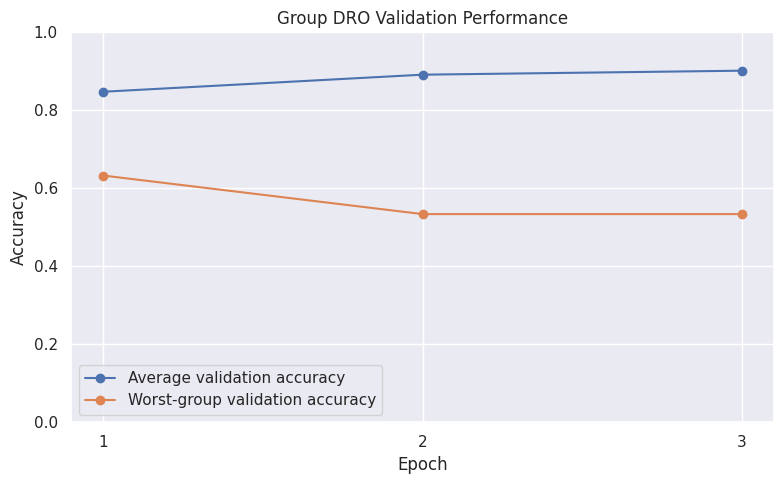

In [13]:
history_path=DRO_DIR/"training_history.csv"
if history_path.exists():
    history=pd.read_csv(history_path); display(history)
    required={"epoch","val_accuracy","val_worst_group_accuracy"}
    miss=required-set(history.columns)
    if miss: raise ValueError(f"Training history missing: {sorted(miss)}")
    plt.figure(figsize=(8,5)); plt.plot(history.epoch,history.val_accuracy,marker="o",label="Average validation accuracy"); plt.plot(history.epoch,history.val_worst_group_accuracy,marker="o",label="Worst-group validation accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Group DRO Validation Performance"); plt.xticks(history.epoch); plt.ylim(0,1); plt.legend(); plt.tight_layout()
    plt.savefig(FIGURE_DIR/"groupdro_validation_history.png",dpi=300,bbox_inches="tight"); plt.show()
else:
    print("training_history.csv not found; skipping this figure.")


In [14]:
comparison_df.to_csv(COMPARISON_DIR/"overall_comparison.csv",index=False)
changes_df.to_csv(COMPARISON_DIR/"metric_changes.csv",index=False)
group_comparison.to_csv(COMPARISON_DIR/"group_comparison.csv",index=False)
print("="*65); print("ERM VS GROUP DRO TEST COMPARISON"); print("="*65)
print(comparison_df.round(4).to_string(index=False))
print("Changes (Group DRO - ERM):")
for m,v in changes.items(): print(f"  {m}: {v:+.4f}")
print(f"ERM worst: {erm_worst.identity} | {erm_worst.label_name} | n={int(erm_worst.n)} | {erm_worst.ERM_accuracy:.4f}")
print(f"Group DRO worst: {dro_worst.identity} | {dro_worst.label_name} | n={int(dro_worst.n)} | {dro_worst.GroupDRO_accuracy:.4f}")


ERM VS GROUP DRO TEST COMPARISON
   Method  Accuracy  Precision  Recall     F1  Worst-group Accuracy
      ERM    0.9227     0.6817  0.6014 0.6390                0.4841
Group DRO    0.8440     0.4069  0.8117 0.5421                0.6515
Changes (Group DRO - ERM):
  Accuracy: -0.0787
  Precision: -0.2748
  Recall: +0.2103
  F1: -0.0970
  Worst-group Accuracy: +0.1674
ERM worst: christian | toxic | n=1254 | 0.4841
Group DRO worst: black | non-toxic | n=3317 | 0.6515
